## Comprobar el entorno de  Qiskit <a id="install"></a>
En este Notebook se utilizar Qiskit para el diseño e implementación de circuitos cuánticos en simuladores y hardware real. Ya suponemos instalado Qiskit v2.0.
Lo primero, se comprueba la versión de Python del entorno y debe ser python>=3.10 para asegurar que sea compatible con la versión de Qiskit:

In [1]:
from platform import python_version

print(python_version())

3.9.21


In [ ]:
import qiskit

print(f"Qiskit version: {qiskit.__version__}")


En este entorno la version de Qiskit `>=2.0.0`

## Imports <a id="imports"></a>


In [3]:
from qiskit import QuantumRegister, QuantumCircuit, ClassicalRegister
from qiskit import transpile
from qiskit.circuit.library import MCXGate
import numpy as np
from qiskit_aer import AerSimulator
from qiskit_aer import Aer
from qiskit.quantum_info import Statevector


# Construcción de funciones binarias. Los min-term.

La idea es considerar exclusivamente los términos que tienen como salida la variable 1, que denominaremos min-terms.

Cada min-término llevará asociada una puerta condicionada diferente. Su composición define la función  f



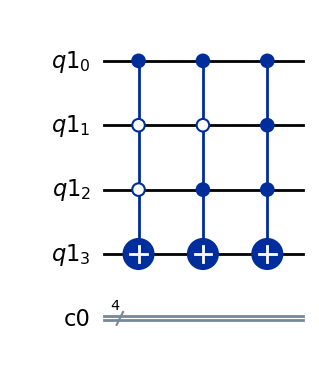

In [4]:
qr = QuantumRegister(4)
cr = ClassicalRegister(4)

qc = QuantumCircuit(qr, cr, name='q')

qc.append(MCXGate(3, ctrl_state=1), qr)
qc.append(MCXGate(3, ctrl_state=5), qr)
qc.append(MCXGate(3, ctrl_state=7), qr)

qc.draw(output='mpl')

In [5]:
# Usar el simulador de vectores de estado
backend = Aer.get_backend('statevector_simulator')

# Ejecutamos el circuito en el simulador
compiled_circuit = transpile(qc, backend)
result = backend.run(compiled_circuit).result()

# Obtenemos el vector de estado resultante
sv = result.get_statevector()

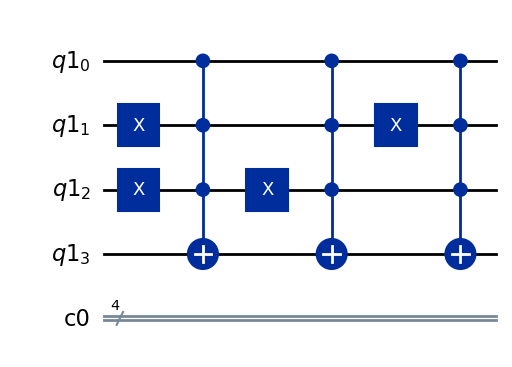

In [6]:
compiled_circuit.draw(output='mpl')

In [7]:
sv

Statevector([1.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
             0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
             0.+0.j, 0.+0.j],
            dims=(2, 2, 2, 2))


In [8]:
sv.draw('latex') 

<IPython.core.display.Latex object>

Para evaluar la funcion |y> = |0>

In [9]:
##comprobamos algunos resulados

In [10]:
sv_ini = Statevector.from_label('0111') # INICIALIZAR StateVector con .from_label()
sv_ini.draw('latex')

<IPython.core.display.Latex object>

In [11]:
# SIN SIMULADOR
sv_ev = sv_ini.evolve(qc) # evolucionar el estado inicial siguiedo el circuito
sv_ev.draw('latex') 

<IPython.core.display.Latex object>

In [12]:
sv_ini = Statevector.from_label('0101') # INICIALIZAR StateVector con .from_label
sv_ini.draw('latex')

<IPython.core.display.Latex object>

In [13]:
# SIN SIMULADOR
sv_ev = sv_ini.evolve(qc) # evolucionar el estado inicial siguiedo el circuito
sv_ev.draw('latex') 

<IPython.core.display.Latex object>